In [3]:
!pip install diffusers transformers accelerate safetensors opencv-python pillow

Using device: cpu
Loading ControlNet...
Loading Stable Diffusion...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]


Please upload your sketch/image:


Saving Nikhil.jpeg to Nikhil.jpeg
Uploaded file: Nikhil.jpeg
Image loaded successfully.
Input sketch:


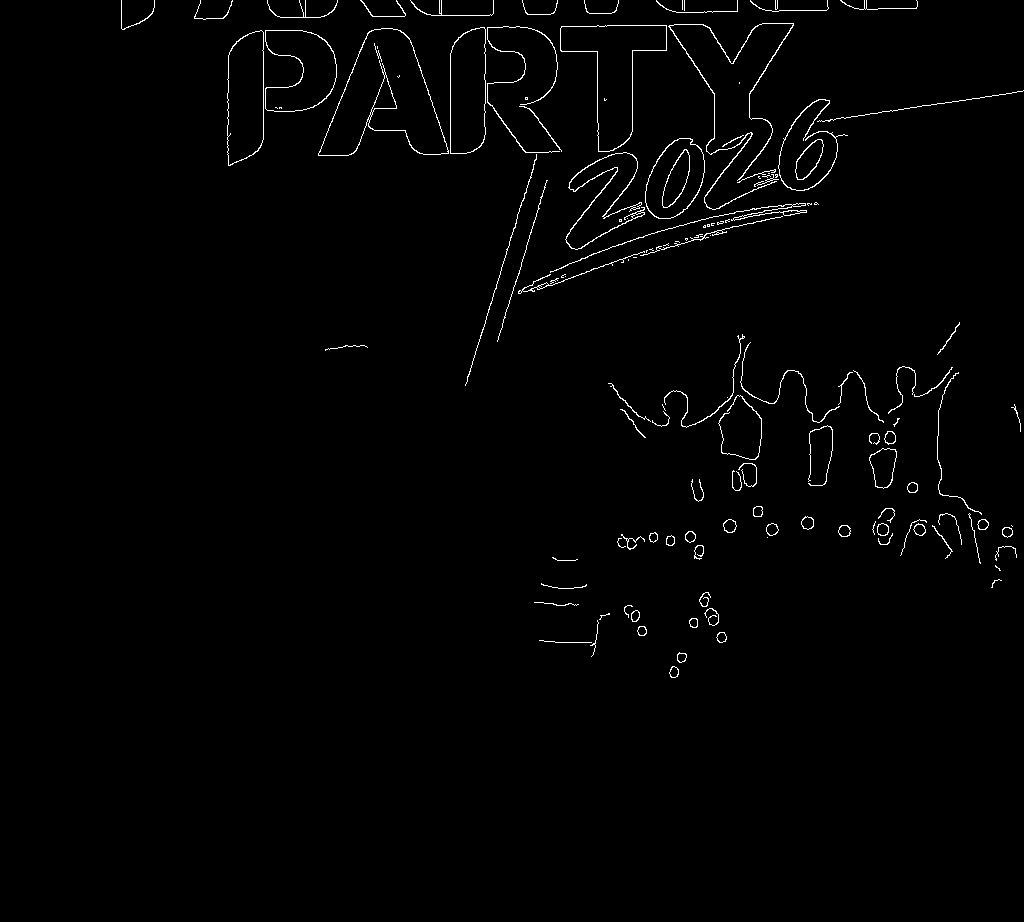


Generating image...
CPU generation may take a long time.


  0%|          | 0/10 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [4]:
import torch
import cv2
from PIL import Image
from google.colab import files

from diffusers import (
    StableDiffusionControlNetPipeline,
    ControlNetModel,
    UniPCMultistepScheduler
)

device = "cpu"
dtype = torch.float32

print("Using device:", device)


print("Loading ControlNet...")

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-scribble",
    torch_dtype=dtype
)


print("Loading Stable Diffusion...")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=dtype
)



pipe.scheduler = UniPCMultistepScheduler.from_config(
    pipe.scheduler.config
)



pipe = pipe.to(device)



print("\nPlease upload your sketch/image:")

uploaded = files.upload()

# Get uploaded file name
input_path = list(uploaded.keys())[0]

print("Uploaded file:", input_path)



img = cv2.imread(
    input_path,
    cv2.IMREAD_GRAYSCALE
)


if img is None:

    print("Error: Could not read the image.")

else:

    print("Image loaded successfully.")

    edges = cv2.Canny(
        img,
        100,
        200
    )


    edges = cv2.cvtColor(
        edges,
        cv2.COLOR_GRAY2RGB
    )



    control_image = Image.fromarray(edges)


    # Display input sketch
    print("Input sketch:")

    display(control_image)

    prompt = (
        "a colorful illustration of a cute anime "
        "character in a fantasy world, vibrant colors"
    )


    print("\nGenerating image...")
    print("CPU generation may take a long time.")


    output = pipe(
        prompt=prompt,
        image=control_image,
        num_inference_steps=10
    ).images[0]


    output.save("colored.png")
    print("\nImage generated successfully!")

    print("Output saved as: colored.png")

    display(output)